# Hipotesis multivariada propuesta por catedra:
A igual capacidad de huéspedes, un alojamiento se alquila más caro si
garantiza mayor independencia: tener una cama para cada persona (no
compartir colchón), mayor cantidad de baños por huésped, y reserva
automática.

In [54]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

listing_dataset = pd.read_csv("listings (1).csv.gz")
calendar_dataset = pd.read_csv("calendar.csv.gz")

In [ ]:
# Confirmamos que 'instant_bookable' solo tiene filas nulas
listing_dataset['instant_bookable'].value_counts(dropna=False)

instant_bookable
NaN    29685
Name: count, dtype: int64

In [10]:
#copiamos el conjunto para preservarlo
preprocessed_dataset = listing_dataset.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)

preprocessed_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 68 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   last_scraped                                  29685 non-null  str    
 2   source                                        29685 non-null  str    
 3   name                                          29685 non-null  str    
 4   description                                   28917 non-null  str    
 5   hosts_time_as_user_years                      29685 non-null  int64  
 6   hosts_time_as_user_months                     29685 non-null  int64  
 7   hosts_time_as_host_years                      29685 non-null  int64  
 8   hosts_time_as_host_months                     29685 non-null  int64  
 9   host_location                                 23105 non-null  str    
 1

### Variables involucradas en hipotesis:

 + instant_bookable (De momento no lo voy a tener en cuenta por que es una columna nula).
 + beds
 + bathrooms
 + accommodates
 + price ó price_quote_price_per_night (la segunda no hace falta la limpieza de caracteres).
 + bathrooms_text???


### Analisis

La fila de ``'instant_bookable'`` es una fila nula en su totalidad por lo tanto, no va a ser tomada en cuenta en el analisis de la hipotesis.

In [19]:
# Miramos cuantas filas vacias tiene cada variable a analizar

cols = ['beds', 'bathrooms', 'accommodates', 'price_quote_price_per_night']
preprocessed_dataset[cols].isna().mean().sort_values()


accommodates                   0.000000
price_quote_price_per_night    0.060367
beds                           0.087014
bathrooms                      0.115917
dtype: float64

In [20]:
cols = ['beds', 'bathrooms', 'accommodates', 'price_quote_price_per_night']

n_antes = len(preprocessed_dataset)
dataset_without_null = preprocessed_dataset.dropna(subset=cols)
dataset_without_null = dataset_without_null[(dataset_without_null['price_quote_price_per_night'] > 0) & (dataset_without_null['accommodates'] > 0)]

print(f"Filas antes: {n_antes} | después: {len(dataset_without_null)} | perdidas: {1 - len(dataset_without_null)/n_antes:.1%}")

Filas antes: 29685 | después: 25256 | perdidas: 14.9%


Viendo que ``'price_quote_price_per_night'`` tiene un 6% de nulos,``'beds'`` un 8,7% y ``'bathrooms'`` un 11,6%, habiendo tantas filas podemos prescindir de ese porcentaje de nulos. Si eliminanos las filas que contienen nulos se pierde un 14,9% porciento de la base. ¿Contenemos esas filas o no?.

In [21]:
descartadas = preprocessed_dataset.drop(dataset_without_null.index)
print(dataset_without_null['price_quote_price_per_night'].median(), descartadas['price_quote_price_per_night'].median())

101419.29000000001 92252.67


La media del precio varia casi 9k pesos (9% de diferencias entre medias), es un cambio leve, preguntar:*¿Es coherente seguir el analisis con las filas que contengan nulas eliminadas?*.

### *Creacion de variables y exloratoria de las mismas*

Para analizar parte de la hipotesis no hace falta crear nuevas variables:
+ Tenemos primero `'camas_para_cada_huesped'`, con una condicion ``'beds'`` >= ``'accommodates'``.
+ Segundo ``'bath_per_huesped'`` = ``'bathrooms'`` / ``'accommodates'``. 

El hecho de que `'camas_para_cada_huesped'` sea una variable dicotomica puede llegar a dar falsos negativos por que la hipotesis dice "no compartir colchon", si en el alojamiento se haya una cama dos plazas esta variable nos indicara false ya que la variable beds cuenta camas no colchones.

In [64]:
# Creo la variable de bath_per_huesped que no tiene tanto analisis ni inferencia como la otra
dataset_without_null['bath_per_huesped'] = dataset_without_null['bathrooms'] / dataset_without_null['accommodates']
dataset_without_null['bath_per_huesped'].describe()

dataset_without_null.groupby('accommodates')['bath_per_huesped'].agg(['mean', 'count'])


,mean,count
accommodates,,
1,1.535803,1201
2,0.552857,12094
3,0.370911,4422
4,0.316375,5177
5,0.314823,958
6,0.304130,799
7,0.295205,143
8,0.301224,194
9,0.280247,45


In [29]:
dataset_without_null['cama_para_cada_uno'] = dataset_without_null['beds'] >= dataset_without_null['accommodates']
dataset_without_null.groupby('accommodates')['cama_para_cada_uno'].agg(['mean', 'count'])

,mean,count
accommodates,,
1,1.000000,1201
2,0.164214,12094
3,0.153324,4422
4,0.107784,5177
5,0.126305,958
6,0.113892,799
7,0.062937,143
8,0.159794,194
9,0.200000,45


In [31]:
dataset_without_null['cama_para_cada_uno'].value_counts()

cama_para_cada_uno
False    20502
True      4754
Name: count, dtype: int64

Tenemos 20502 False (81%) y 4754 True (19%), por mas que el porcentaje de True's parezca pequeño si lo comparamos con el otro lado, la cantidad de muestras es suficiente como para generar una conclusion fiable.

Usaremos las "muestras" con accommodates de entre 2-6 ya que son los que concentran la mayoria de las filas y el porcentaje de True's para mayor capacidad nos da muy poca cantidad de filas que no modificarian a el analisis el que se tomen o no. Asi como tambien todo alquiler para una persona tampoco lo tendremos en cuenta por que es algo trivial ya que todas tienen un colchon para una persona.


In [30]:
df_comp = dataset_without_null[dataset_without_null['accommodates'].between(2, 6)]
print(len(df_comp), len(df_comp) / len(dataset_without_null))

23450 0.9284922394678492


Si nos quedamos con las filas que mencionamos aun asi mantendriamos el 92,85% de lo que ya teniamos (23450 filas).
Analicemos si el hecho de que el alojamiento sea mas caro solo por el hecho de contar con camas para cada uno de los huespedes.

In [32]:
df_comp.groupby(['accommodates', 'cama_para_cada_uno'])['price_quote_price_per_night'].median().unstack()

cama_para_cada_uno,False,True
accommodates,,
2,90000.72,84993.370
3,101636.20,105571.805
4,125122.00,124932.830
5,172567.00,161482.000
6,203978.75,155344.520


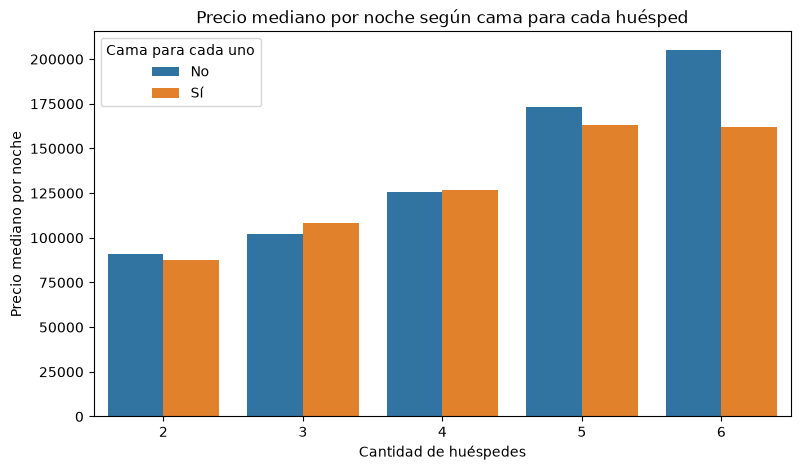

In [55]:
#Grafico que explica mejor la tabla

plt.figure(figsize=(9, 5))
sns.barplot(data=df_comp2, x='accommodates', y='price_quote_price_per_night',
            hue='cama_para_cada_uno', estimator='median', errorbar=None)
plt.title('Precio mediano por noche según cama para cada huésped')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('Precio mediano por noche')
plt.legend(title='Cama para cada uno', labels=['No', 'Sí'])
plt.show()

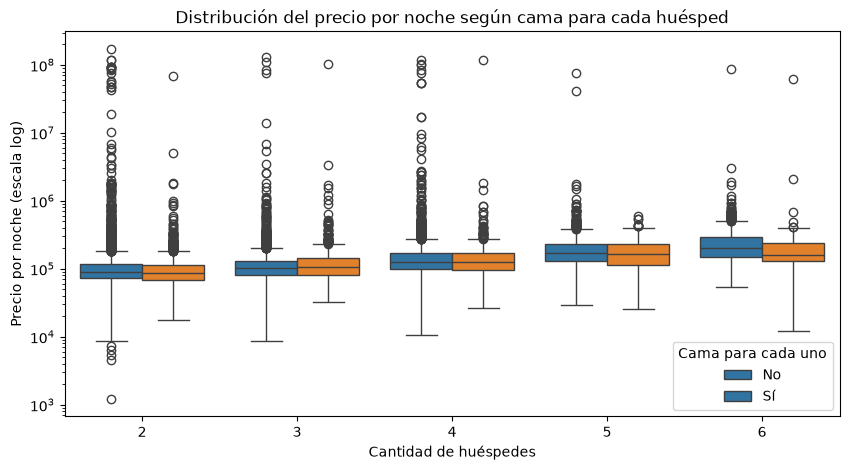

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_comp2, x='accommodates', y='price_quote_price_per_night',
            hue='cama_para_cada_uno')
plt.yscale('log')
plt.title('Distribución del precio por noche según cama para cada huésped')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('Precio por noche (escala log)')
plt.legend(title='Cama para cada uno', labels=['No', 'Sí'])
plt.show()

# Tengo un error en la leyenda del graf. lo intente acomodar pero me da problemas el seaborn

Como vemos no es asi y estaria rompiendo la hipotesis si solo decimos que el precio sube por la cantida de camas, en el unico caso donde eso se cumple es para accommodates = 3 y tampoco es que aumente por demasia el precio.

Cambiando a la variable `'bathrooms'`, tiremos un scaterplot para ver como se distribuye con respecto a la cantidad de huespedes.

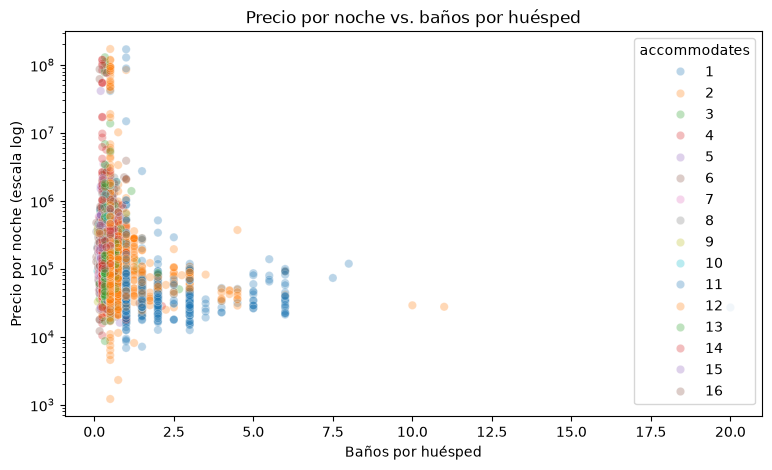

In [65]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=dataset_without_null, x='bath_per_huesped', y='price_quote_price_per_night',
                hue='accommodates', palette='tab10', alpha=0.3)
plt.yscale('log')
plt.title('Precio por noche vs. baños por huésped')
plt.xlabel('Baños por huésped')
plt.ylabel('Precio por noche (escala log)')
plt.show()

In [38]:
df_comp.groupby(['accommodates', 'bathrooms'])['price_quote_price_per_night'].agg(['median', 'count'])

median  count
accommodates bathrooms                    
2            0.5          58683.250     34
             1.0          88390.000  10837
             1.5         115830.000    747
             2.0         102169.585    286
             2.5         134782.530     36
             3.0          56696.000     66
             3.5          38031.615      8
             4.0          50625.000     17
             4.5          41480.720      2
             5.0          77680.250     14
             5.5          80633.000      1
             6.0          79759.500     26
             7.0          82251.000      1
             8.0          36564.670      5
             8.5          47416.670      3
             9.0          40576.000      7
             12.0         66692.285      2
             20.0         29061.940      1
             22.0         27648.000      1
3            0.5          54258.415      4
             1.0          98860.670   3745
             1.5         133911.290    425
             2.0         127667.405    210
             2.5         203979.000     17
             3.0          69620.500     16
             3.5        1395361.560      1
             4.0         115309.235      2
             6.0          87097.000      1
             8.0          50087.000      1
4            0.5         129263.665      2
             1.0         113908.000   3519
             1.5         146078.500    809
             2.0         181918.335    676
             2.5         271481.910    125
             3.0         205975.000     33
             3.5         265694.040      4
             4.0          30967.465      8
             8.5          28350.600      1
5            0.5         202499.560      1
             1.0         138664.165    398
             1.5         181317.200    195
             2.0         198534.880    258
             2.5         304001.045     62
             3.0         296928.000     25
             3.5         381759.535     12
             4.0         396308.135      6
             5.0          70980.000      1
6            1.0         141911.000    242
             1.5         199073.000    144
             2.0         211953.680    233
             2.5         309738.670     81
             3.0         277845.000     65
             3.5         467607.250     22
             4.0         230568.920      6
             4.5         677371.000      1
             5.0          75222.000      1
             5.5         774671.000      1
             6.0        1074704.500      2
             8.5          31169.800      1

Analizando la metadata de AirBnB, cuando la variable `bathrooms` tiene valores con decimal quiere notar que hay un medio baño, ¿que es un medio baño?. Que tiene lo esencial para que sea un baño, un inodoro y una bacha, no cuenta con ducha ni bañera.
Podemos pensar que para los valores altos de la variable estamos hablando de ser un lugar con mas "medio baños" que con baños completos y viendo que, pero lo que me esta mostrando esto es primero que nada que claramente hay una tendencia de a mayor cantidad de baños mayor 

La variable `'bath_per_huesped'` acota en rangos mas legibles en %, siendo 1 el hecho de que hay un baño para cada huesped, si esta por debajo de 1 es que hay menos y si esta por encima es que hay mas baños que huespedes.

In [ ]:
# bathrooms_text nos da informacion de que tipo de baños tiene el alojamiento
df_comp['bathrooms_text'].value_counts().head(15)

bathrooms_text
1 bath               17873
1.5 baths             2224
2 baths               1579
1 private bath         590
2.5 baths              308
1 shared bath          275
3 baths                141
1.5 shared baths        95
2 shared baths          82
3 shared baths          62
3.5 baths               40
6 shared baths          24
4 baths                 22
4 shared baths          17
Private half-bath       17
Name: count, dtype: int64

``bathroom_text`` nos podria estar diciendo que en un alojamiento hay baños compartidos y baños privados, no se llega a especificar si dentro del lugar se hayan ambos tipos de baños sino que la aplicacion le obliga a poner al host si un baño es o compartido o privado.
Para unificar y simplicar filas podemos decir que las filas donde no se especifican el tipo de baños los tomamos como privados.

Hace falta tambien sacar las filas donde hay exageradamente mas baños que capacidad de huespedes, puede ser un error de tipeo u otra cosa pero sin embargo son casos exepcionales, es decir, que hay muy pocos y solo estan ahi para tirar la media para arriba.

In [ ]:
# Cantidad de filas que quedan si eliminamos los baños compartidos y los casos donde
# hay muchos mas baños que huespedes
df_comp2 = df_comp[(~df_comp['banio_compartido']) & (df_comp['bath_per_huesped'] <= 1)].copy()
print(len(df_comp2), len(df_comp2) / len(df_comp))

22764 0.9707462686567164


In [50]:
df_comp2['tramo_banios'] = pd.cut(df_comp2['bath_per_huesped'], bins=[0, 0.25, 0.5, 1])

df_comp2.groupby(['accommodates', 'tramo_banios'], observed=True)['price_quote_price_per_night'].agg(['median', 'count'])

median  count
accommodates tramo_banios                   
2            (0.0, 0.25]    71758.000     19
             (0.25, 0.5]    88955.670  10613
             (0.5, 1.0]    123237.500    887
3            (0.0, 0.25]    54258.415      4
             (0.25, 0.5]   101521.000   4143
             (0.5, 1.0]    130587.000    227
4            (0.0, 0.25]   114092.085   3502
             (0.25, 0.5]   162577.560   1470
             (0.5, 1.0]    269728.250    161
5            (0.0, 0.25]   138694.125    396
             (0.25, 0.5]   194839.365    512
             (0.5, 1.0]    343366.800     43
6            (0.0, 0.25]   165860.910    380
             (0.25, 0.5]   238437.125    376
             (0.5, 1.0]    446258.500     31

Los tramos podemos categorizarlos como:
+ (0.0, 0.25]: Pocos baños
+ (0.25, 0.5]: Intermedio
+ (0.5, 1]: Muchos baños

Vemos como claramente aislando el resto de variables involucradas, el que haya mas baños hace que el precio del lugar sea mayor, tambien por algo logico el hecho de que haya mas baños tambien quiere decir que el establecimiento es mas grande por ende ya sin necesidad de tener que analizar probabilisticamente podemos deducir que si bien hay una tendencia a mayor precio cuanto mas baños tambien el precio este inducido por el tamaño del alojamiento que conlleva el tener mas baños justamente.

Preguntar que hacer con la posibilidad de baños compartidos y baños privados, si contar solo los baños privados o tambien tener en cuenta los compartidos:

*No lo analizamos todavía. Hasta ahora banio_compartido solo lo usamos como filtro: marcamos esos casos y los excluimos, así que tampoco entró en el modelo. Nunca comparamos el precio de baño compartido contra privado.*

*Es una buena pregunta, porque encaja con tu hipótesis: un baño compartido es lo opuesto a la independencia, así que a igual capacidad debería abaratar el alquiler. Tenés dos opciones:*

*Dejarlo como filtro y aclarar en el informe que se excluyeron por ser un caso distinto (pocos casos, 2,6%).*
*Estudiarlo como una variable más de la hipótesis, comparando precios.*



In [ ]:
# Grafico de barras

plt.figure(figsize=(9, 5))
sns.barplot(data=df_comp2, x='accommodates', y='price_quote_price_per_night',
            hue='tramo_banios', estimator='median', errorbar=None)
plt.title('Precio mediano por noche según baños por huésped')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('Precio mediano por noche')
plt.show()

In [ ]:
# Boxplots

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_comp2, x='accommodates', y='price_quote_price_per_night',
            hue='tramo_banios')
plt.yscale('log')
plt.title('Distribución del precio por noche según baños por huésped')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('Precio por noche (escala log)')
plt.show()

In [ ]:
# Grafico de lineas

orden = ['(0.0, 0.25]', '(0.25, 0.5]', '(0.5, 1.0]']
tabla['tramo_banios'] = pd.Categorical(tabla['tramo_banios'], categories=orden, ordered=True)
tabla = tabla.sort_values(['accommodates', 'tramo_banios'])

plt.figure(figsize=(9, 5))
sns.lineplot(data=tabla, x='tramo_banios', y='mediana', hue='accommodates',
             marker='o', palette='tab10')
plt.xticks(range(3), ['Pocos\n(0 a 0,25)', 'Intermedio\n(0,25 a 0,5)', 'Muchos\n(0,5 a 1)'])
plt.title('Precio mediano por noche según baños por huésped')
plt.xlabel('Baños por huésped (tramo)')
plt.ylabel('Precio mediano por noche')
plt.legend(title='Huéspedes')
plt.show()

-------------------------------------------------------------------------------------------------------------------------------

**Aca comienzo a hacer la regresion lineal multiple**

                            OLS Regression Results                            
Dep. Variable:             log_precio   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                     806.6
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:27:28   Log-Likelihood:                -18091.
No. Observations:               22764   AIC:                         3.620e+04
Df Residuals:                   22757   BIC:                         3.625e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               10.7898 

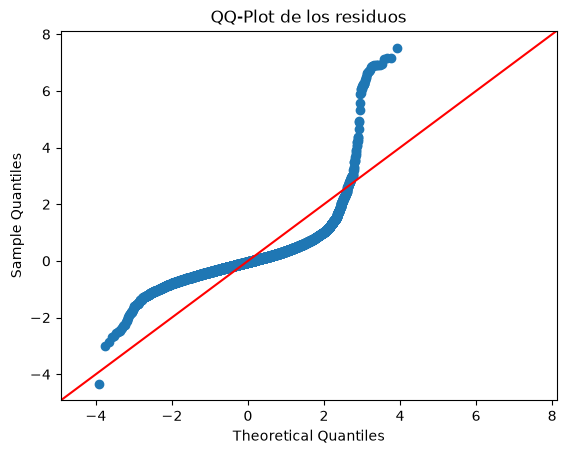

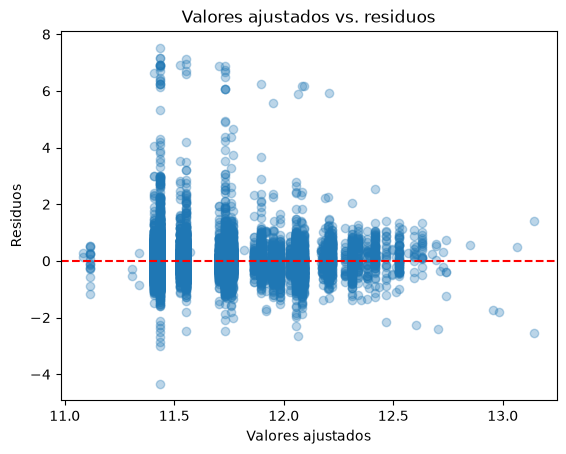

In [67]:
import numpy as np
import statsmodels.formula.api as smf

df_comp2['log_precio'] = np.log(df_comp2['price_quote_price_per_night'])
df_comp2['cama_para_cada_uno'] = df_comp2['cama_para_cada_uno'].astype(int)

modelo = smf.ols(
    'log_precio ~ C(accommodates) + cama_para_cada_uno + bath_per_huesped',
    data=df_comp2
).fit()
print(modelo.summary())

import statsmodels.api as sm
sm.qqplot(modelo.resid, line='45')
plt.title('QQ-Plot de los residuos')
plt.show()

plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores ajustados')
plt.ylabel('Residuos')
plt.title('Valores ajustados vs. residuos')
plt.show()

Lo que suelta la tabla de OSL respalda lo analizado en la exploratoria de las variables y vemos como `'bath_per_huesped'` tiene un coeficiente de *1,29* y `'cama_para_cada_uno'` cuenta con un coef. del *-0.029* es decir, que como encontramos anteriormente el hecho de que haya mas camas (colchones), practicamente no se asocia con el precio de la vivienda por mas que afecta, el incremento es tan chico que no es significativo y no apoya la idea de la hipotesis en cuanto a las camas.

De todas formas si analizamos el valor `R-squared` de la tabla vemos como el modelo explica un 17,5% dentro del contexto de la hipotesis, pero tampoco no nos confirma que las variables analizadas no sirven para validar la hipotesis ya que los coeficientes si la sustentan en cierta parte.